# Generative Project - Milestone 1: COCO 2017 Setup & Dataset
**Goal:** Prepare exactly 5,000 distinct image-caption pairs from COCO 2017 validation, confirm the PyTorch/Diffusers/CLIP environment, encode captions with CLIP, and generate five baseline text-to-image samples using Stable Diffusion v1.5.

**Run in Google Colab.** Before starting choose **Runtime → Change runtime type → T4 GPU (or another GPU)**. Execute cells from top to bottom. Official dataset downloads are large (~0.8 GB images and ~0.25 GB annotation archives). The model weights are also several GB.

**Important:** The separate OpenAI CLIP ViT-B/32 encoder below is an *embedding demonstration*; Stable Diffusion v1.5 uses its own CLIP-based text encoder internally. Do not claim these embeddings were directly fed into the diffusion pipeline.

## 1. Install dependencies

In [4]:
%pip install -q \
    "pandas==2.2.3" \
    "Pillow==11.3.0" \
    diffusers transformers accelerate \
    safetensors ftfy regex matplotlib tqdm

%pip install -q git+https://github.com/openai/CLIP.git

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


## 2. Check hardware and create directories

In [9]:
import os, json, re, csv, gc, shutil, subprocess, zipfile
from pathlib import Path
import numpy as np
import pandas as pd
from PIL import Image
import torch

# Project directory
if Path("/content").is_dir():
    ROOT = Path("/content/coco_milestone1")
else:
    ROOT = Path.cwd() / "coco_milestone1"

DATA = ROOT / "data"
SAMPLES = ROOT / "samples"

DATA.mkdir(parents=True, exist_ok=True)
SAMPLES.mkdir(parents=True, exist_ok=True)

# Hardware detection
print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
elif torch.backends.mps.is_available():
    print("Apple MPS GPU available")
else:
    print("CPU mode")

print("Project directory:", ROOT)
print("Directories created successfully!")

PyTorch: 2.11.0+cu130
CUDA available: True
GPU: Tesla T4
Project directory: /content/coco_milestone1
Directories created successfully!


## 3. Download **official COCO 2017 validation** images and annotations

Sources:
- http://images.cocodataset.org/zips/val2017.zip
- http://images.cocodataset.org/annotations/annotations_trainval2017.zip

Download the validation images only, **not** `train2017.zip` (~19 GB). We extract the relevant caption JSON from the annotation archive.

In [10]:
URLS = {
    'val2017.zip': 'http://images.cocodataset.org/zips/val2017.zip',
    'annotations_trainval2017.zip': 'http://images.cocodataset.org/annotations/annotations_trainval2017.zip',
}

def download_if_missing(filename, url):
    target = DATA / filename
    if not target.exists() or target.stat().st_size == 0:
        subprocess.run(['wget', '--continue', '--show-progress', url, '-O', str(target)], check=True)
    else:
        print('Already downloaded:', target)
    return target

img_zip = download_if_missing('val2017.zip', URLS['val2017.zip'])
ann_zip = download_if_missing('annotations_trainval2017.zip', URLS['annotations_trainval2017.zip'])

img_folder = DATA / 'val2017'
if not img_folder.exists() or len(list(img_folder.glob('*.jpg'))) < 5000:
    with zipfile.ZipFile(img_zip) as z:
        z.extractall(DATA)
print('Image files:', len(list(img_folder.glob('*.jpg'))))

captions_path = DATA / 'annotations' / 'captions_val2017.json'
if not captions_path.exists():
    with zipfile.ZipFile(ann_zip) as z:
        z.extract('annotations/captions_val2017.json', DATA)
print('Annotations:', captions_path)

Image files: 5000
Annotations: /content/coco_milestone1/data/annotations/captions_val2017.json


## 4. Clean & preprocess 5,000 image-caption pairs

Each distinct COCO validation image has several captions. Select the **first annotation by annotation ID** per image, trim/normalize whitespace, reject empty descriptions or unreadable images, and keep one row per image. This produces **5,000 pairs rather than ~25,000 pairs**. The code checks counts before exporting a CSV and JSONL manifest.

In [11]:
with open(captions_path, 'r', encoding='utf-8') as f:
    coco = json.load(f)

images_by_id = {img['id']: img for img in coco['images']}
first_caption_by_id = {}
for ann in sorted(coco['annotations'], key=lambda a: a['id']):
    first_caption_by_id.setdefault(ann['image_id'], ann['caption'])

records = []
for image_id in sorted(images_by_id):
    imeta = images_by_id[image_id]
    img_path = img_folder / imeta['file_name']
    caption = re.sub(r'\s+', ' ', first_caption_by_id.get(image_id, '')).strip()
    if not caption or not img_path.is_file():
        continue
    try:
        with Image.open(img_path) as im:
            im.verify()
    except Exception as exc:
        print('Skipping invalid image:', img_path, str(exc))
        continue
    records.append({
        'image_id': image_id,
        'file_name': imeta['file_name'],
        'image_path': str(img_path),
        'caption': caption,
    })

pairs = pd.DataFrame(records)
assert 1000 <= len(pairs) <= 5000, f'Unexpected pair count: {len(pairs)}'
assert pairs.image_id.is_unique, 'Expected exactly one caption for each image.'
print('Image-caption pairs:', len(pairs))
if len(pairs) != 5000:
    print('WARNING: Fewer than 5,000 clean pairs; inspect missing/corrupt images.')

csv_path = DATA / 'coco_val2017_5000_pairs.csv'
jsonl_path = DATA / 'coco_val2017_5000_pairs.jsonl'
pairs.to_csv(csv_path, index=False)
with open(jsonl_path, 'w', encoding='utf-8') as f:
    for row in records:
        f.write(json.dumps(row, ensure_ascii=False) + '\n')

display(pairs.head())
print('Saved:', csv_path, jsonl_path)

Image-caption pairs: 5000


,image_id,file_name,image_path,caption
0,139,000000000139.jpg,/content/coco_milestone1/data/val2017/00000000...,A woman stands in the dining area at the table.
1,285,000000000285.jpg,/content/coco_milestone1/data/val2017/00000000...,A big burly grizzly bear is show with grass in...
2,632,000000000632.jpg,/content/coco_milestone1/data/val2017/00000000...,"Bedroom scene with a bookcase, blue comforter ..."
3,724,000000000724.jpg,/content/coco_milestone1/data/val2017/00000000...,A stop sign is mounted upside-down on it's post.
4,776,000000000776.jpg,/content/coco_milestone1/data/val2017/00000000...,"Three teddy bears, each a different color, snu..."


Saved: /content/coco_milestone1/data/coco_val2017_5000_pairs.csv /content/coco_milestone1/data/coco_val2017_5000_pairs.jsonl


## 5. Visual inspection of COCO samples

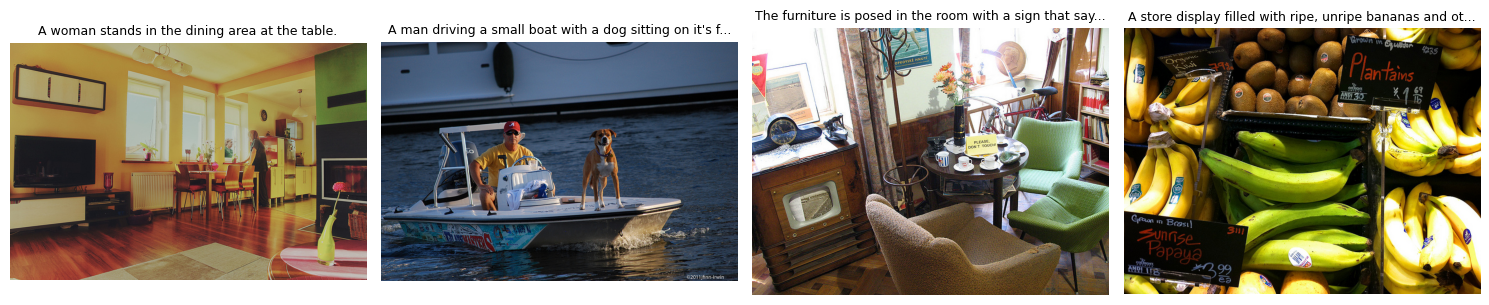

In [8]:
import matplotlib.pyplot as plt
sample_rows = pairs.iloc[np.linspace(0, len(pairs)-1, 4, dtype=int)]
fig, axes = plt.subplots(1, 4, figsize=(15, 4))
for ax, (_, row) in zip(axes, sample_rows.iterrows()):
    ax.imshow(Image.open(row.image_path).convert('RGB'))
    ax.set_title(row.caption[:55] + ('...' if len(row.caption) > 55 else ''), fontsize=9)
    ax.axis('off')
plt.tight_layout()
plt.show()

## 6. Baseline text-to-embedding: OpenAI CLIP ViT-B/32
Encode five captions, inspect feature shape, L2 normalization, and cosine similarity. This is independent of Stable Diffusion's built-in text encoder.

In [14]:
%pip install -q git+https://github.com/openai/CLIP.git

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


In [15]:
import clip
import torch.nn.functional as F

clip_device = 'cpu'  # Save GPU RAM for the diffusion model.
clip_model, _ = clip.load('ViT-B/32', device=clip_device)
clip_model.eval()

captions_for_embedding = pairs.caption.iloc[:5].tolist()
tokens = clip.tokenize(captions_for_embedding, truncate=True).to(clip_device)
with torch.no_grad():
    features = clip_model.encode_text(tokens).float()
    embeddings = F.normalize(features, dim=-1)
    cosine_similarity = embeddings @ embeddings.T

print('Tokens:', tuple(tokens.shape))
print('Text embedding shape:', tuple(embeddings.shape))
print('L2 norms:', embeddings.norm(dim=-1).tolist())
display(pd.DataFrame(cosine_similarity.cpu().numpy()).round(3))
np.save(DATA / 'clip_text_embeddings_5.npy', embeddings.cpu().numpy())

del clip_model, features, tokens, embeddings
import gc
gc.collect()

100%|███████████████████████████████████████| 338M/338M [00:07<00:00, 46.8MiB/s]


Tokens: (5, 77)
Text embedding shape: (5, 512)
L2 norms: [0.9999998211860657, 0.9999999403953552, 0.9999999403953552, 1.0, 0.9999999403953552]


,0,1,2,3,4
0,1.000,0.531,0.473,0.523,0.461
1,0.531,1.000,0.453,0.528,0.612
2,0.473,0.453,1.000,0.416,0.505
3,0.523,0.528,0.416,1.000,0.490
4,0.461,0.612,0.505,0.490,1.000


0

## 7. Five baseline prompt-to-image tests (GPU required)
The following **five fixed COCO-style prompts** are baseline test inputs. The images will be created by pretrained Stable Diffusion v1.5; **no fine-tuning or COCO-based training is performed** in Milestone 1. Save each output, its prompt, and seed as evidence for the submission.

In [2]:
import torch
import pandas as pd
from pathlib import Path

ROOT = Path("/content/coco_milestone1")
DATA = ROOT / "data"
SAMPLES = ROOT / "samples"

SAMPLES.mkdir(parents=True, exist_ok=True)

print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

print("Ready for image generation!")

PyTorch: 2.11.0+cu130
CUDA available: True
GPU: Tesla T4
Ready for image generation!


In [3]:
from diffusers import StableDiffusionPipeline

if not torch.cuda.is_available():
    raise RuntimeError('Select Runtime > Change runtime type > GPU in Colab, then rerun the notebook.')

MODEL_ID = 'stable-diffusion-v1-5/stable-diffusion-v1-5'
pipe = StableDiffusionPipeline.from_pretrained(MODEL_ID, torch_dtype=torch.float16)
pipe = pipe.to('cuda')
pipe.enable_attention_slicing()

TEST_PROMPTS = [
    'A brown dog running through a grassy field in sunlight.',
    'Two people riding bicycles along a city street.',
    'A red bus traveling down a road on a cloudy day.',
    'A plate of fresh fruit on a wooden kitchen table.',
    'A small boat floating on a calm lake near mountains.',
]

results = []
for i, prompt in enumerate(TEST_PROMPTS, start=1):
    seed = 2026 + i
    generator = torch.Generator(device='cuda').manual_seed(seed)
    result = pipe(
        prompt=prompt,
        num_inference_steps=25,
        guidance_scale=7.5,
        height=512,
        width=512,
        generator=generator,
    )
    image = result.images[0]
    output_path = SAMPLES / f'prompt_{i:02}.png'
    image.save(output_path)
    results.append({'run': i, 'prompt': prompt, 'seed': seed, 'image_file': output_path.name, 'model': MODEL_ID})
    print('Saved:', output_path)

result_table = pd.DataFrame(results)
result_table.to_csv(SAMPLES / 'test_runs.csv', index=False)
display(result_table)

/usr/local/lib/python3.13/dist-packages/diffusers/utils/deprecation_utils.py:23: FutureWarning: `torch_dtype` is deprecated and will be removed in version 1.0.0. Please use `dtype` instead.
  deprecate("torch_dtype", "1.0.0", _TORCH_DTYPE_DEPRECATION_MESSAGE)


model_index.json:   0%|          | 0.00/541 [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 15 files:   0%|          | 0/15 [00:00<?, ?it/s]

Loading pipeline components...:   0%|          | 0/7 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

... (8 outputs left out)

Saved: /content/coco_milestone1/samples/prompt_04.png


  0%|          | 0/25 [00:00<?, ?it/s]

Saved: /content/coco_milestone1/samples/prompt_05.png


,run,prompt,seed,image_file,model
0,1,A brown dog running through a grassy field in ...,2027,prompt_01.png,stable-diffusion-v1-5/stable-diffusion-v1-5
1,2,Two people riding bicycles along a city street.,2028,prompt_02.png,stable-diffusion-v1-5/stable-diffusion-v1-5
2,3,A red bus traveling down a road on a cloudy day.,2029,prompt_03.png,stable-diffusion-v1-5/stable-diffusion-v1-5
3,4,A plate of fresh fruit on a wooden kitchen table.,2030,prompt_04.png,stable-diffusion-v1-5/stable-diffusion-v1-5
4,5,A small boat floating on a calm lake near moun...,2031,prompt_05.png,stable-diffusion-v1-5/stable-diffusion-v1-5


## 8. Display the five generated test images

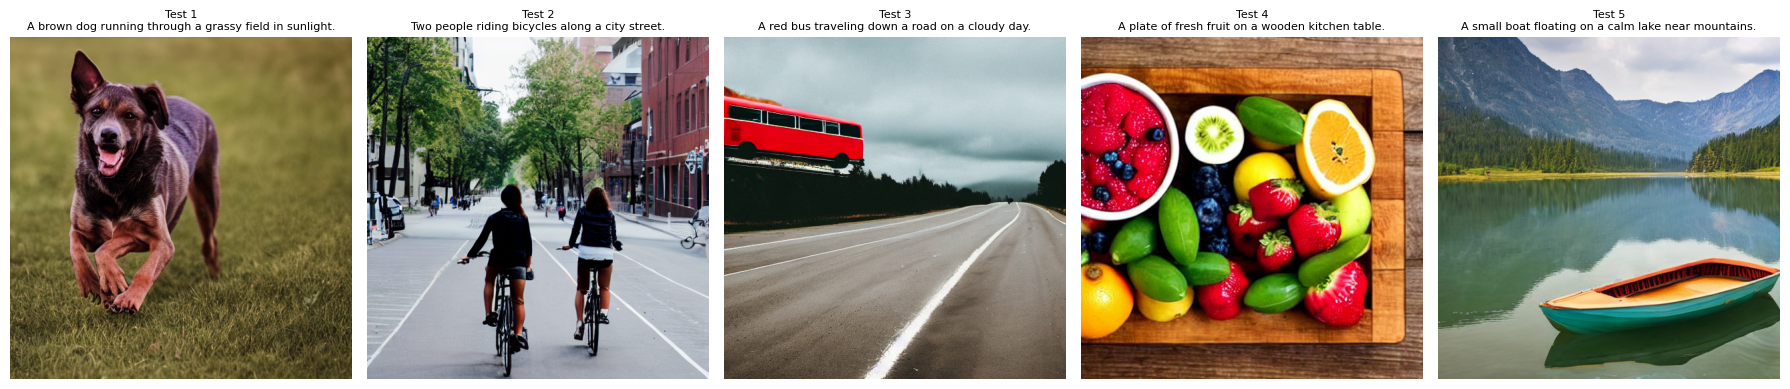

In [5]:
import matplotlib.pyplot as plt
from PIL import Image

fig, axes = plt.subplots(1, 5, figsize=(18, 4.5))

for ax, row in zip(axes, results):
    image = Image.open(SAMPLES / row["image_file"])
    ax.imshow(image)
    ax.set_title(
        f"Test {row['run']}\n{row['prompt']}",
        fontsize=8
    )
    ax.axis("off")

plt.tight_layout()

fig.savefig(
    SAMPLES / "five_test_runs_overview.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()

## 9. Export your evidence
After running the notebook, download a ZIP containing the **manifest CSV/JSONL, CLIP embeddings, and generated samples**. Do not commit the 5,000 source images or large model weights to GitHub. Upload code/notebook, small metadata, and five generated example images instead. Replace the proposal's role placeholders and GitHub URL with real information before submitting.

In [16]:
import zipfile
from pathlib import Path
from google.colab import files

ROOT = Path("/content/coco_milestone1")
output_zip = Path("/content/COCO_Milestone1_Results.zip")

selected_files = [
    "data/coco_val2017_5000_pairs.csv",
    "data/coco_val2017_5000_pairs.jsonl",
    "data/clip_text_embeddings_5.npy",
    "samples/test_runs.csv",
    "samples/five_test_runs_overview.png",
]

selected_files += [
    f"samples/prompt_{i:02d}.png"
    for i in range(1, 6)
]

with zipfile.ZipFile(output_zip, "w", zipfile.ZIP_DEFLATED) as z:
    for relative_path in selected_files:
        source = ROOT / relative_path

        if source.is_file():
            z.write(source, arcname=relative_path)
            print("Added:", relative_path)
        else:
            print("Missing:", relative_path)

print("ZIP created:", output_zip)
files.download(str(output_zip))

Added: data/coco_val2017_5000_pairs.csv
Added: data/coco_val2017_5000_pairs.jsonl
Added: data/clip_text_embeddings_5.npy
Added: samples/test_runs.csv
Added: samples/five_test_runs_overview.png
Added: samples/prompt_01.png
Added: samples/prompt_02.png
Added: samples/prompt_03.png
Added: samples/prompt_04.png
Added: samples/prompt_05.png
ZIP created: /content/COCO_Milestone1_Results.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>